In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

## Clean Data

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [5]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"],errors="coerce")

In [8]:
print(df["TotalCharges"].dtype)

float64


In [9]:
df["TotalCharges"].isna().sum() # so before .isna() didn't show null values because the vales might have been empty string "" / string with blank spaces "  ", for these cases .isna() don't show Nan


np.int64(11)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [11]:
# why these 11 values are missing in total charges - it is because the tenure for these 11 customers are 0 , so they might have joined the service today 

df[df["TotalCharges"].isna()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [12]:
# drop the rows 

df = df.dropna(subset=["TotalCharges"])

In [13]:
df.shape

(7032, 21)

In [14]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [15]:
# duplicate rows

df.duplicated().sum()

np.int64(0)

In [16]:
# drop customer ID column

df = df.drop(columns ="customerID",axis=1)

In [17]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## EDA

In [18]:
# correlation heatmap

corr = df.corr(numeric_only=True)

<Axes: >

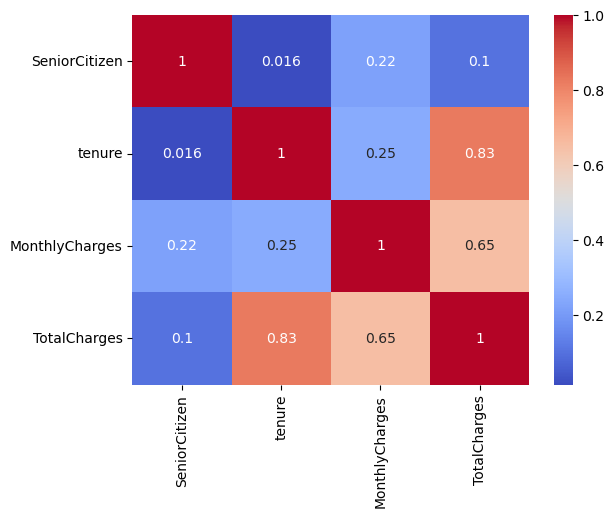

In [19]:
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

In [20]:
# imbalance data :- 70-30 moderatrly imbalanced data

df["Churn"].value_counts()

Churn
No     5163
Yes    1869
Name: count, dtype: int64

<Axes: xlabel='Churn', ylabel='count'>

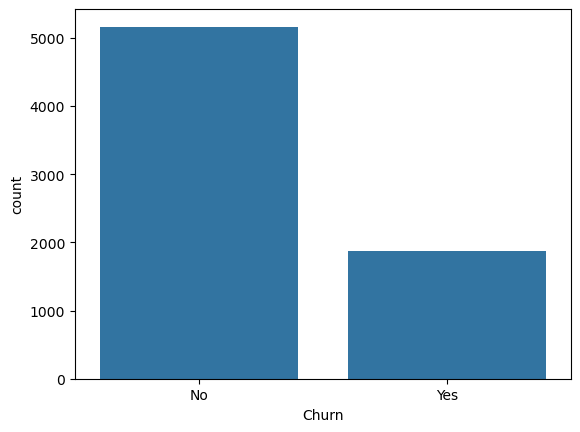

In [21]:
# churn distribution 

sns.countplot(
    x="Churn",
    data = df
)

<Axes: xlabel='Contract', ylabel='count'>

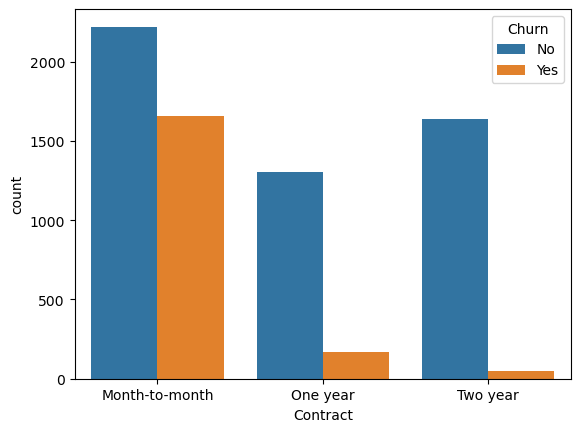

In [22]:
# contract vs churn

sns.countplot(
    x="Contract",
    hue = "Churn",
    data = df
)

In [23]:
pd.crosstab(df["Contract"],df["Churn"],normalize="index")*100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.722826,11.277174
Two year,97.151335,2.848665


In [24]:
pd.crosstab(df["Churn"],df["Contract"],normalize="columns")*100

# the longer the contract duration the lower the probability of customer churn

Contract,Month-to-month,One year,Two year
Churn,,,
No,57.290323,88.722826,97.151335
Yes,42.709677,11.277174,2.848665


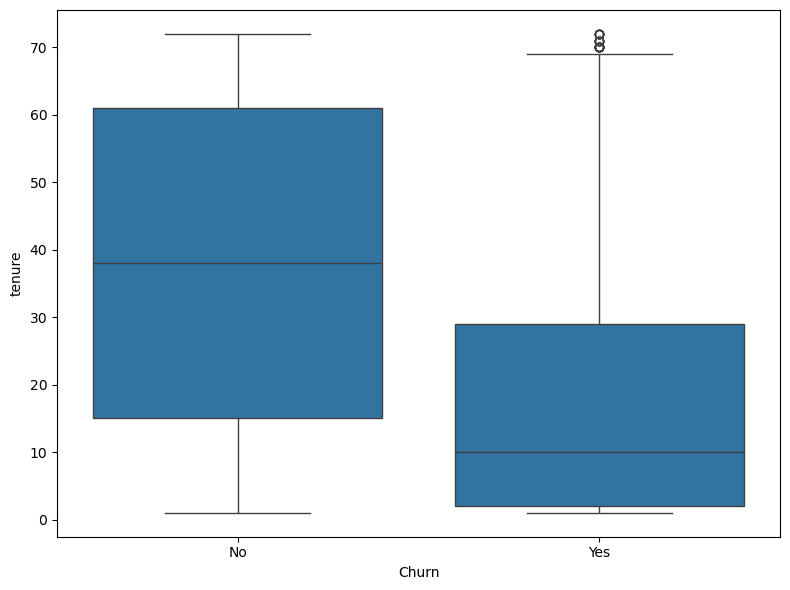

In [25]:
# tenure vs churn

plt.figure(figsize=(8,6))
sns.boxplot(
    x = "Churn",
    y= "tenure",
    data = df
)

plt.tight_layout()

# customer with lower tenure are more likely to churn

<Axes: xlabel='tenure', ylabel='Count'>

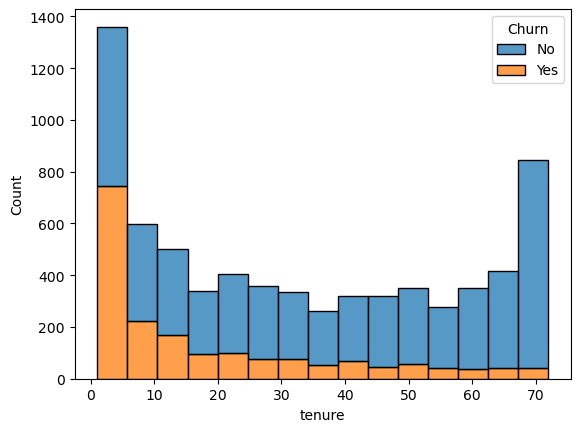

In [26]:
sns.histplot(
    x="tenure",
    data =df,
    hue="Churn",
    multiple="stack"
)

<Axes: xlabel='Churn', ylabel='MonthlyCharges'>

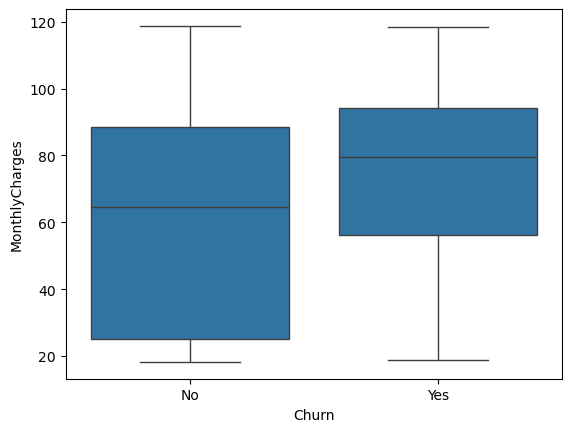

In [27]:
# MonthlyCharges vs churn

sns.boxplot(
    x="Churn",
    y="MonthlyCharges",
    data =df
)

# customer with high montly charges are more likely to churn

In [28]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<Axes: xlabel='Churn', ylabel='TotalCharges'>

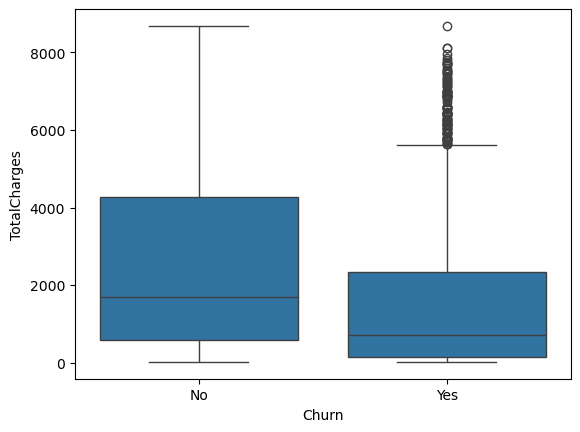

In [29]:
sns.boxplot(
    x="Churn",
    y="TotalCharges",
    data =df
)

In [30]:
# important features acc to eda : contract , tenure , monthly charges 

In [31]:
for col in df.columns:
    print(col,":",df[col].unique())

gender : ['Female' 'Male']
SeniorCitizen : [0 1]
Partner : ['Yes' 'No']
Dependents : ['No' 'Yes']
tenure : [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26 39]
PhoneService : ['No' 'Yes']
MultipleLines : ['No phone service' 'No' 'Yes']
InternetService : ['DSL' 'Fiber optic' 'No']
OnlineSecurity : ['No' 'Yes' 'No internet service']
OnlineBackup : ['Yes' 'No' 'No internet service']
DeviceProtection : ['No' 'Yes' 'No internet service']
TechSupport : ['No' 'Yes' 'No internet service']
StreamingTV : ['No' 'Yes' 'No internet service']
StreamingMovies : ['No' 'Yes' 'No internet service']
Contract : ['Month-to-month' 'One year' 'Two year']
PaperlessBilling : ['Yes' 'No']
PaymentMethod : ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
MonthlyCharges : [29.85 56.95 53.85 ... 63.1  44.2  78

## Encoding

In [32]:
# multiple category cols

from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder()
cat_cols = ["MultipleLines","InternetService","OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies","Contract","PaymentMethod"]
enc_cols = ohe.fit_transform(df[cat_cols])

In [33]:
enc_df = pd.DataFrame(enc_cols.toarray(),columns=ohe.get_feature_names_out(cat_cols),index=df.index)

In [34]:
enc_df.head()

,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [35]:
df_encoded = pd.concat([df.drop(columns=cat_cols),enc_df],axis =1)

In [36]:
df_encoded.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,Female,0,Yes,No,1,No,Yes,29.85,29.85,No,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,Male,0,No,No,34,Yes,No,56.95,1889.50,No,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,Male,0,No,No,2,Yes,Yes,53.85,108.15,Yes,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3,Male,0,No,No,45,No,No,42.30,1840.75,No,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,Female,0,No,No,2,Yes,Yes,70.70,151.65,Yes,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [37]:
# binary cols

df_encoded["gender"] = df_encoded["gender"].map({"Female":0,"Male":1})
df_encoded["Churn"] = df_encoded["Churn"].map({"No":0,"Yes":1})
df_encoded["Partner"] = df_encoded["Partner"].map({"No":0,"Yes":1})
df_encoded["Dependents"] = df_encoded["Dependents"].map({"No":0,"Yes":1})
df_encoded["PhoneService"] = df_encoded["PhoneService"].map({"No":0,"Yes":1})
df_encoded["PaperlessBilling"] = df_encoded["PaperlessBilling"].map({"No":0,"Yes":1})

In [38]:
df_encoded.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,1,0,0,0,2,1,1,53.85,108.15,1,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,0,0,0,0,2,1,1,70.70,151.65,1,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


## train test split

In [39]:
X = df_encoded.drop("Churn",axis=1)
y = df_encoded["Churn"]

In [40]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [41]:
X_train.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
6030,0,0,0,0,43,0,1,49.05,2076.20,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3410,1,0,0,0,3,1,0,53.40,188.70,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
5483,0,0,1,0,55,1,1,77.75,4458.15,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
5524,1,0,1,1,45,1,0,54.65,2553.70,1.0,...,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
6337,0,0,1,1,55,1,0,100.90,5448.60,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


## Scaling

In [186]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scale = scaler.fit_transform(X_train)
X_test_scale = scaler.transform(X_test)


## model training

## Logistic Regression

In [43]:
# logistic regression 
from sklearn.linear_model import LogisticRegression

model1 = LogisticRegression()
model1.fit(X_train_scale,y_train)

LogisticRegression()

In [44]:
y_pred = model1.predict(X_test_scale)

In [45]:
from sklearn.metrics import accuracy_score , precision_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import recall_score, f1_score

print("model1 accuracy :",accuracy_score(y_test,y_pred))
print("model1 precision :",precision_score(y_test,y_pred))
print("model1 cm :",confusion_matrix(y_test,y_pred))
print("model1 recall :",recall_score(y_test,y_pred))
print("model1 f1 :",f1_score(y_test,y_pred))

model1 accuracy : 0.7867803837953091
model1 precision : 0.6185897435897436
model1 cm : [[914 119]
 [181 193]]
model1 recall : 0.516042780748663
model1 f1 : 0.5626822157434402


## Decision Tree

In [46]:
# Decision tree

from sklearn.tree import DecisionTreeClassifier

model2 = DecisionTreeClassifier()
model2.fit(X_train,y_train)

DecisionTreeClassifier()

In [47]:
y_pred = model2.predict(X_test)

In [48]:
print("model2 accuracy :",accuracy_score(y_test,y_pred))
print("model2 precision :",precision_score(y_test,y_pred))
print("model2 cm :",confusion_matrix(y_test,y_pred))
print("model2 recall :",recall_score(y_test,y_pred))
print("model2 f1 :",f1_score(y_test,y_pred))

model2 accuracy : 0.7185501066098081
model2 precision : 0.4719387755102041
model2 cm : [[826 207]
 [189 185]]
model2 recall : 0.4946524064171123
model2 f1 : 0.4830287206266319


In [49]:
# pre-pruning 

from sklearn.model_selection import GridSearchCV

param_grid = {
    "max_depth": [2,3,4,5,6,7],
    "min_samples_split": [10,15,20]
}

grid = GridSearchCV(
    estimator = DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5
)

grid.fit(X_train,y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'max_depth': [2, 3, 4, 5, 6, 7],
                         'min_samples_split': [10, 15, 20]})

In [50]:
best_model = grid.best_estimator_

In [51]:
y_pred = best_model.predict(X_test)

In [52]:
print("m21 accuracy:",accuracy_score(y_test,y_pred))
print("model21 precision :",precision_score(y_test,y_pred))
print("model21 cm :",confusion_matrix(y_test,y_pred))
print("model21 recall :",recall_score(y_test,y_pred))
print("model21 f1 :",f1_score(y_test,y_pred))

m21 accuracy: 0.7732764747690121
model21 precision : 0.5749318801089919
model21 cm : [[877 156]
 [163 211]]
model21 recall : 0.5641711229946524
model21 f1 : 0.5695006747638327


In [53]:
# post pruning 

full_tree = DecisionTreeClassifier(random_state = 42)
full_tree.fit(X_train,y_train)

DecisionTreeClassifier(random_state=42)

In [54]:
path = full_tree.cost_complexity_pruning_path(X_train,y_train)

In [55]:
ccp_alphas = path.ccp_alphas

In [56]:
param_grid = {
    "ccp_alpha":ccp_alphas[:-1]
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state = 42),
    param_grid = param_grid,
    cv=5,
    n_jobs = -1,
    refit = True
    
)

# n_jobs controls parallel processing , n_jobs = -1 tells scikit-learn to use all available CPU cores , allowing multiple hyperparameter
# combinations and cross-validation folds to be evaluated in parallel, which speeds up GridSearchCV
# n_jobs=1 :- use one CPU core (default)

# refit=True tells GridSearchCV to retain the estimator using the best hyperparameters on the entire training dataset after cross-validation
# is complete , this gives us a final model (best_estimator_) that is ready to make predictions on the test set

In [57]:
grid.fit(X_train,y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
             param_grid={'ccp_alpha': array([0.00000000e+00, 0.00000000e+00, 1.18518519e-05, 2.96296296e-05,
       3.17460317e-05, 3.80952381e-05, 4.74074074e-05, 5.33333333e-05,
       5.71428571e-05, 5.92592593e-05, 5.92592593e-05, 6.77248677e-05,
       7.40740741e-05, 8.48484848e-05, 8.85791715e-05, 9.31216931e-05,
       9...
       6.00672754e-04, 6.27088194e-04, 6.32028684e-04, 6.54421449e-04,
       6.54655776e-04, 6.64891009e-04, 6.72419950e-04, 6.76768008e-04,
       6.79897628e-04, 7.24686429e-04, 7.30434783e-04, 7.35443875e-04,
       8.48225171e-04, 9.86653880e-04, 1.01547040e-03, 1.04176487e-03,
       1.22890325e-03, 1.52861306e-03, 1.81887535e-03, 2.37421631e-03,
       2.46619899e-03, 2.65781014e-03, 3.58835900e-03, 6.95446413e-03,
       1.11647142e-02, 2.03097046e-02])})

In [58]:
grid.best_params_

{'ccp_alpha': np.float64(0.0012289032488553217)}

In [59]:
best_model = grid.best_estimator_

In [60]:
y_pred = best_model.predict(X_test)

In [61]:
print("m22 accuracy:",accuracy_score(y_test,y_pred))
print("model22 precision :",precision_score(y_test,y_pred))
print("model22 cm :",confusion_matrix(y_test,y_pred))
print("model22 recall :",recall_score(y_test,y_pred))
print("model22 f1 :",f1_score(y_test,y_pred))

m22 accuracy: 0.7782515991471215
model22 precision : 0.581151832460733
model22 cm : [[873 160]
 [152 222]]
model22 recall : 0.5935828877005348
model22 f1 : 0.5873015873015873


## Random Forest

In [62]:


from sklearn.ensemble import RandomForestClassifier

param_grid = {
    "n_estimators" : [100,200,300], 
    "max_depth" : [10,20,30],
    "min_samples_split" : [2,5,10],
    "max_features" : ["sqrt"]
}

grid = GridSearchCV(
    RandomForestClassifier(class_weight = "balanced",random_state=42),
    param_grid=param_grid,
    cv=5,
    n_jobs=-1,
    scoring="recall"
    
)

In [63]:
grid.fit(X_train,y_train)

GridSearchCV(cv=5,
             estimator=RandomForestClassifier(class_weight='balanced',
                                              random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [10, 20, 30], 'max_features': ['sqrt'],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 300]},
             scoring='recall')

In [64]:
# if we want to know what different attributes are stored inside the grid object :-  dir(grid)
dir(grid)

['__abstractmethods__',
 '__annotations__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setstate__',
 '__sizeof__',
 '__sklearn_clone__',
 '__sklearn_tags__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_abc_impl',
 '_build_request_for_signature',
 '_check_feature_names',
 '_check_n_features',
 '_check_refit_for_multimetric',
 '_doc_link_module',
 '_doc_link_template',
 '_doc_link_url_param_generator',
 '_estimator_type',
 '_format_results',
 '_get_default_requests',
 '_get_doc_link',
 '_get_metadata_request',
 '_get_param_names',
 '_get_routed_params_for_fit',
 '_get_scorers',
 '_get_tags',
 '_more_tags',
 '_parameter_constraints',
 '_repr_html_',
 '_repr

In [65]:
best_model = grid.best_estimator_

In [66]:
# to know which parameters are used inside the model , we can use model.get_params()

model = RandomForestClassifier()
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

In [67]:
y_pred = best_model.predict(X_test)

In [68]:
print("model 3 accuracy:",accuracy_score(y_test,y_pred))
print("model 3 precision :",precision_score(y_test,y_pred))
print("model 3 cm :",confusion_matrix(y_test,y_pred))
print("model 3 recall :",recall_score(y_test,y_pred))
print("model 3 f1 :",f1_score(y_test,y_pred))

# the recall value is quite low , to increase it we use scoring = "recall", & since the is not balanced we can use RandomForestClassifier(class_weight = "balanced")
# it teels model to pay more attention to the minority class


model 3 accuracy: 0.7547974413646056
model 3 precision : 0.5284872298624754
model 3 cm : [[793 240]
 [105 269]]
model 3 recall : 0.7192513368983957
model 3 f1 : 0.609286523216308


In [69]:
# after using scoring = "recall", RandomForestClassifier(class_weight = "balanced")

print("model 3 accuracy:",accuracy_score(y_test,y_pred))
print("model 3 precision :",precision_score(y_test,y_pred))
print("model 3 cm :",confusion_matrix(y_test,y_pred))
print("model 3 recall :",recall_score(y_test,y_pred))
print("model 3 f1 :",f1_score(y_test,y_pred))

# f1 score tells whether the balance between precision and recall has improved

model 3 accuracy: 0.7547974413646056
model 3 precision : 0.5284872298624754
model 3 cm : [[793 240]
 [105 269]]
model 3 recall : 0.7192513368983957
model 3 f1 : 0.609286523216308


In [70]:
# what to look for in confusion matrix :- not just look for making TP value bigger , it's about understanding what changed and what trade-off's you made
"""
TN FP
FN TP
"""
# we want to correctly identify customers who will churn
# we want :- TP to be high, FN to be low

# but there is usually a trade-off : 
# to increase TP , the model often predicts "yes" more frequently , that can also increase FP : customers who were actually going to stay but model predicted they would churn

# is TP increasing ? yes -> good 
# is FN decresing ? yes -> very important
# did FP increase too much ? -> check this
# is TN still reasonably high ? yes -> good

'\nTN FP\nFN TP\n'

## XGBoost

In [74]:
from xgboost import XGBClassifier

In [75]:
# first we train the baseline model & then compare it to the random forest and if not perform better we do hyperparameter tuning

model = XGBClassifier(
    eval_metric = "logloss",
    random_state = 42
)

model.fit(X_train,y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [76]:
y_pred = model.predict(X_test)

In [77]:
print("model 4 accuracy:",accuracy_score(y_test,y_pred))
print("model 4 precision :",precision_score(y_test,y_pred))
print("model 4 cm :",confusion_matrix(y_test,y_pred))
print("model 4 recall :",recall_score(y_test,y_pred))
print("model 4 f1 :",f1_score(y_test,y_pred))


model 4 accuracy: 0.7654584221748401
model 4 precision : 0.569620253164557
model 4 cm : [[897 136]
 [194 180]]
model 4 recall : 0.48128342245989303
model 4 f1 : 0.5217391304347826


In [78]:
# tune the model

param_grid = {
    "n_estimators":[100,200],
    "max_depth": [3,5,7],
    "learning_rate": [0.01,0.1],
    "subsample": [0.8,1],
    "colsample_bytree": [0.8,1]
}


In [79]:
# scale-pos-weight :- just like we did class_weight in random forest
# scale-pos-weight = no. of negative class samples / no. of positive class samples

neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
scale_pos_weight = neg/pos

print(scale_pos_weight)

2.762541806020067


In [80]:
xgb = XGBClassifier(
    scale_pos_weight = scale_pos_weight,
    random_state =42
)

grid = GridSearchCV(
    estimator = xgb,
    param_grid = param_grid,
    scoring = "recall",
    cv=5,
    n_jobs = -1
)

In [81]:
grid.fit(X_train,y_train)

GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=None, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=Non...
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.8, 1],
                         'learning_rate': [0.01, 0.1], 'max_depth': [3, 5, 7],
                         'n_estimators': [100, 200], 'subsample': [0.8, 1]},
             scoring='recall')

In [82]:
best_model = grid.best_estimator_

In [83]:
grid.best_params_

{'colsample_bytree': 1,
 'learning_rate': 0.01,
 'max_depth': 3,
 'n_estimators': 100,
 'subsample': 0.8}

In [84]:
y_pred = best_model.predict(X_test)

In [85]:
print("model 4 accuracy:",accuracy_score(y_test,y_pred))
print("model 4 precision :",precision_score(y_test,y_pred))
print("model 4 cm :",confusion_matrix(y_test,y_pred))
print("model 4 recall :",recall_score(y_test,y_pred))
print("model 4 f1 :",f1_score(y_test,y_pred))


model 4 accuracy: 0.7157071783937455
model 4 precision : 0.4794952681388013
model 4 cm : [[703 330]
 [ 70 304]]
model 4 recall : 0.8128342245989305
model 4 f1 : 0.6031746031746031


## Compare models

In [86]:
comparison = pd.DataFrame({
    "Models": [
        "Logistic Regression",
        "Decision Tree",
        "DT pre-pruning",
        "DT post-pruning",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [0.78,0.71,0.77,0.77,0.75,0.71],
    "Precision": [0.61,0.47,0.57,0.58,0.52,0.47],
    "Recall": [0.51,0.5,0.56,0.59,0.71,0.81],
    "F1": [0.56,0.48,0.56,0.58,0.6,0.6]
})

comparison

,Models,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.78,0.61,0.51,0.56
1,Decision Tree,0.71,0.47,0.50,0.48
2,DT pre-pruning,0.77,0.57,0.56,0.56
3,DT post-pruning,0.77,0.58,0.59,0.58
4,Random Forest,0.75,0.52,0.71,0.60
5,XGBoost,0.71,0.47,0.81,0.60


In [ ]:
# so for our project XGBoost wins 

## Final model - XGBoost

In [142]:
# train the final model

final_model = grid.best_estimator_ # we don't do final_model.fit() becoz itis already fit

In [143]:
# evaluate it one last time

y_pred = final_model.predict(X_test)

In [144]:
print("final model accuracy:",accuracy_score(y_test,y_pred))
print("final model precision :",precision_score(y_test,y_pred))
print("final model cm :",confusion_matrix(y_test,y_pred))
print("final model recall :",recall_score(y_test,y_pred))
print("final model f1 :",f1_score(y_test,y_pred))


final model accuracy: 0.7157071783937455
final model precision : 0.4794952681388013
final model cm : [[703 330]
 [ 70 304]]
final model recall : 0.8128342245989305
final model f1 : 0.6031746031746031


In [145]:
accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)

# Model Analysis & Interpretation

## 1) Analyze Feature Importance

In [97]:
importance = pd.DataFrame({
    "features": X_train.columns,
    "importance": final_model.feature_importances_
})

importance = importance.sort_values(
    by = "importance",
    ascending = False
)

importance.head(10)

,features,importance
33,Contract_Month-to-month,0.456200
13,InternetService_Fiber optic,0.100487
15,OnlineSecurity_No,0.063541
24,TechSupport_No,0.063346
4,tenure,0.036598
35,Contract_Two year,0.035368
32,StreamingMovies_Yes,0.033697
7,MonthlyCharges,0.033038
38,PaymentMethod_Electronic check,0.027527
29,StreamingTV_Yes,0.026014


<Axes: ylabel='features'>

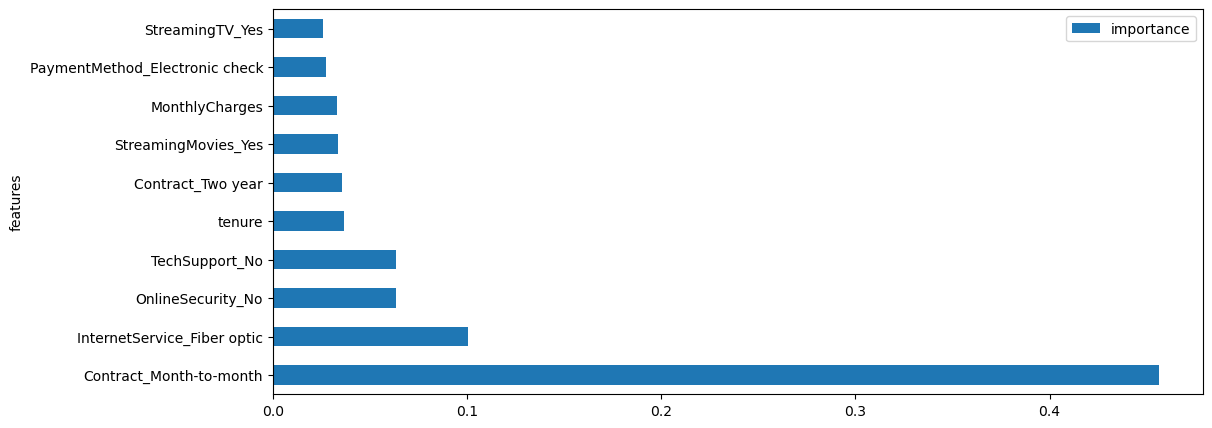

In [100]:
# plot

importance.head(10).plot(
    x="features",
    y="importance",
    kind="barh",
    figsize=(12,5)
)

<Axes: xlabel='Contract_Month-to-month', ylabel='count'>

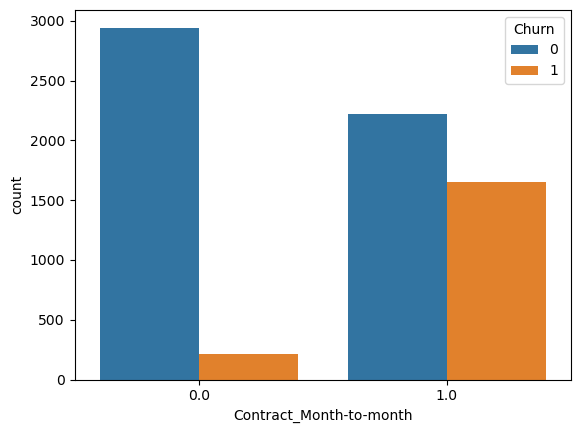

In [101]:
# Contract_Month-to-month is the most important feature

sns.countplot(
    data = df_encoded,
    x="Contract_Month-to-month",
    hue="Churn"

)

In [102]:
pd.crosstab(df_encoded["Contract_Month-to-month"],df_encoded["Churn"],normalize="index")*100

Churn,0,1
Contract_Month-to-month,,
0.0,93.221413,6.778587
1.0,57.290323,42.709677


In [103]:
# customers on month-to-month contract churn much more frequently than customers on other contract tupes

## 2) Error Analysis

In [135]:
pred = final_model.predict(X_test)
wrong_pred = X_test[y_test != pred]
correct_pred = X_test[y_test == pred]

In [109]:
wrong_pred.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3223,1,0,1,0,3,0,0,29.80,94.4,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3469,0,1,0,0,15,1,1,91.50,1400.3,1.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2173,1,0,0,0,4,1,0,86.05,308.1,1.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3257,1,0,0,0,22,1,1,93.20,2157.3,1.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4042,1,0,0,0,5,1,1,51.35,262.3,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [107]:
wrong_pred.describe()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.00000,400.000000,400.000000,400.000000,400.000000,...,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.00000,400.000000,400.000000,400.000000
mean,0.515000,0.215000,0.397500,0.195000,24.895000,0.91000,0.670000,71.016500,2096.156250,0.470000,...,0.530000,0.095000,0.375000,0.880000,0.100000,0.020000,0.17750,0.157500,0.455000,0.210000
std,0.500401,0.411337,0.489994,0.396697,21.668706,0.28654,0.470802,26.706104,2095.114584,0.499724,...,0.499724,0.293582,0.484729,0.325369,0.300376,0.140175,0.38257,0.364728,0.498595,0.407818
min,0.000000,0.000000,0.000000,0.000000,1.000000,0.00000,0.000000,19.050000,19.050000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,4.750000,1.00000,0.000000,50.237500,242.487500,0.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
50%,1.000000,0.000000,0.000000,0.000000,18.500000,1.00000,1.000000,76.925000,1400.425000,0.000000,...,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
75%,1.000000,0.000000,1.000000,0.000000,42.000000,1.00000,1.000000,92.225000,3408.925000,1.000000,...,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.00000,0.000000,1.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,72.000000,1.00000,1.000000,118.350000,8127.600000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000


In [111]:
correct_pred.describe()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
count,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.00000,1007.000000,1007.000000,1007.000000,...,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000
mean,0.488580,0.150943,0.525323,0.334657,35.894737,0.905660,0.57001,62.891112,2402.322542,0.462761,...,0.375372,0.247269,0.377358,0.432969,0.239325,0.327706,0.268123,0.231380,0.279047,0.221450
std,0.500118,0.358172,0.499606,0.472105,24.979571,0.292446,0.49532,30.567759,2336.608830,0.498859,...,0.484460,0.431639,0.484967,0.495733,0.426883,0.469610,0.443202,0.421924,0.448753,0.415429
min,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.00000,18.700000,18.800000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,12.500000,1.000000,0.00000,25.775000,466.500000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,1.000000,0.000000,34.000000,1.000000,1.00000,69.200000,1427.550000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.000000,1.000000,1.000000,60.000000,1.000000,1.00000,88.750000,4094.950000,1.000000,...,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,72.000000,1.000000,1.00000,118.600000,8670.100000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [112]:
# another way for showing wrong prediction datapoints

results = X_test.copy()

results["actual"] = y_test
results["predicted"] = pred

error = results[results["actual"] != results["predicted"]]


In [114]:
error.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,actual,predicted
3223,1,0,1,0,3,0,0,29.80,94.4,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0,1
3469,0,1,0,0,15,1,1,91.50,1400.3,1.0,...,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0,1
2173,1,0,0,0,4,1,0,86.05,308.1,1.0,...,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0,1
3257,1,0,0,0,22,1,1,93.20,2157.3,1.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0,1
4042,1,0,0,0,5,1,1,51.35,262.3,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0,1


In [115]:
# how many predictions were wrong

len(error)

400

In [116]:
# # how many predictions were right

len(correct_pred)

1007

In [117]:
# make a confusion matrix 

pd.crosstab(results["actual"],results["predicted"])

predicted,0,1
actual,,
0,703,330
1,70,304


In [118]:
# TN = 703, FP = 330, FN = 70, TP = 304
# FN = 70 is relatively a smaller number , company would spend the money on FP = 330 rather than lowering the recall value and increasing FN 


In [132]:
false_negative = results[
        (results["actual"] == 1)&
        (results["predicted"] == 0)

]

In [133]:
false_negative.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,actual,predicted
4734,1,0,1,1,39,1,0,80.00,3182.95,1.0,...,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1,0
4513,0,1,1,1,72,1,0,92.45,6440.25,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1,0
6996,0,0,1,1,41,1,1,66.50,2728.60,1.0,...,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1,0
5900,1,0,1,1,37,0,0,40.20,1448.80,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1,0
544,1,0,0,0,13,0,1,45.55,597.00,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1,0


In [121]:
len(false_negative)

70

In [122]:
false_negative.describe()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,actual,predicted
count,70.000000,70.000000,70.00000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,...,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.0,70.0
mean,0.514286,0.157143,0.50000,0.314286,38.614286,0.800000,0.714286,70.510714,3079.276429,0.271429,...,0.528571,0.314286,0.571429,0.114286,0.228571,0.271429,0.342857,0.157143,1.0,0.0
std,0.503405,0.366563,0.50361,0.467583,20.486328,0.402888,0.455016,28.843374,2398.259496,0.447907,...,0.502787,0.467583,0.498445,0.320455,0.422944,0.447907,0.478091,0.366563,0.0,0.0
min,0.000000,0.000000,0.00000,0.000000,5.000000,0.000000,0.000000,19.750000,219.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,0.0
25%,0.000000,0.000000,0.00000,0.000000,19.000000,1.000000,0.000000,49.650000,938.050000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,0.0
50%,1.000000,0.000000,0.50000,0.000000,39.000000,1.000000,1.000000,65.950000,2593.325000,0.000000,...,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,0.0
75%,1.000000,0.000000,1.00000,1.000000,54.750000,1.000000,1.000000,100.000000,5216.237500,1.000000,...,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.0,0.0
max,1.000000,1.000000,1.00000,1.000000,72.000000,1.000000,1.000000,118.350000,8127.600000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,0.0


In [123]:
correct_pred.describe() # TP + TN

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
count,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.00000,1007.000000,1007.000000,1007.000000,...,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000
mean,0.488580,0.150943,0.525323,0.334657,35.894737,0.905660,0.57001,62.891112,2402.322542,0.462761,...,0.375372,0.247269,0.377358,0.432969,0.239325,0.327706,0.268123,0.231380,0.279047,0.221450
std,0.500118,0.358172,0.499606,0.472105,24.979571,0.292446,0.49532,30.567759,2336.608830,0.498859,...,0.484460,0.431639,0.484967,0.495733,0.426883,0.469610,0.443202,0.421924,0.448753,0.415429
min,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.00000,18.700000,18.800000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,12.500000,1.000000,0.00000,25.775000,466.500000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,1.000000,0.000000,34.000000,1.000000,1.00000,69.200000,1427.550000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.000000,1.000000,1.000000,60.000000,1.000000,1.00000,88.750000,4094.950000,1.000000,...,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,72.000000,1.000000,1.00000,118.600000,8670.100000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [124]:
false_negative["Contract_Month-to-month"].value_counts(normalize=True)

Contract_Month-to-month
0.0    0.685714
1.0    0.314286
Name: proportion, dtype: float64

In [125]:
correct_pred["Contract_Month-to-month"].value_counts(normalize=True)

Contract_Month-to-month
0.0    0.567031
1.0    0.432969
Name: proportion, dtype: float64

In [134]:
false_negative["InternetService_Fiber optic"].value_counts(normalize=True)


InternetService_Fiber optic
0.0    0.614286
1.0    0.385714
Name: proportion, dtype: float64

In [136]:
correct_pred["InternetService_Fiber optic"].value_counts(normalize=True)

InternetService_Fiber optic
0.0    0.617676
1.0    0.382324
Name: proportion, dtype: float64

## SHAP

In [154]:
import shap

explainer = shap.TreeExplainer(final_model) 
# "My trained model is an XGBoost tree model. Learn how this model makes decisions."
# explainer becomes an object that knows everything about your trained XGBoost model.

shap_values = explainer.shap_values(X_test)
# Now SHAP analyzes every row in your test data.
"""
contains a SHAP value for

every customer
every feature
"""

"""
Suppose your target is

1 = Churn
0 = No Churn

Positive SHAP value = +0.45 means This feature pushed the customer towards churn.
Negative SHAP value = -0.32 means This feature pushed the customer towards staying.
"""

'\nSuppose your target is\n\n1 = Churn\n0 = No Churn\n\nPositive SHAP value = +0.45 means This feature pushed the customer towards churn.\nNegative SHAP value = -0.32 means This feature pushed the customer towards staying.\n'

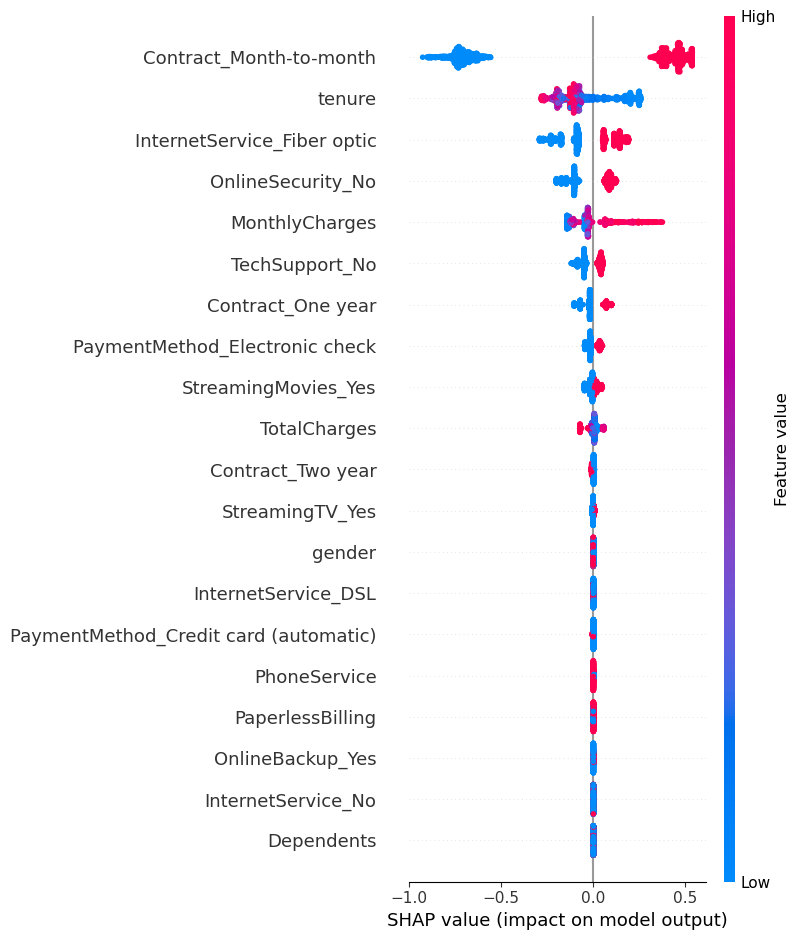

In [155]:
shap.summary_plot(shap_values, X_test) 
# features are arranged in decreasing order of their importance
# 1) when contract-month-to-month = 1 , shap value = high +ve , customer with month-to-month are more likely to churn
# 2) when tenure is high , the customer is less likely to churn , when it is low , customer is more likely to churn

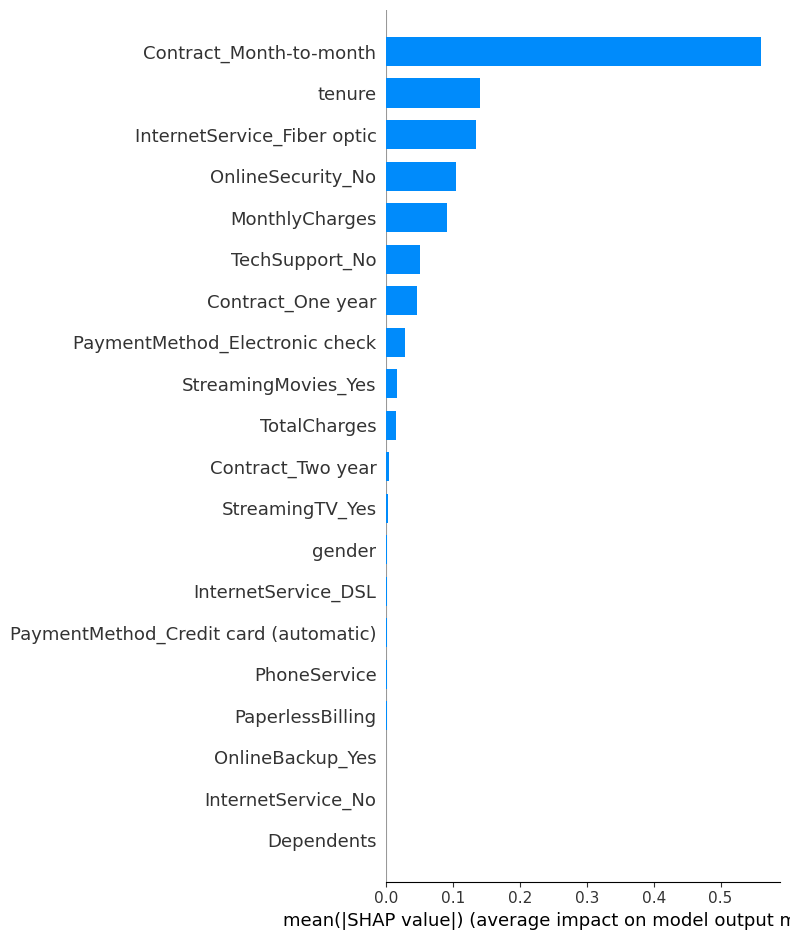

In [156]:
shap.summary_plot(shap_values,X_test,plot_type="bar")
# it ranks features by average importance

# Saving the model

In [137]:
import joblib

In [138]:
# save the final trained model

joblib.dump(final_model,"xgboost_customer_churn.pkl") # 'pkl' :- pickle

['xgboost_customer_churn.pkl']

In [187]:
# save standardscaler

joblib.dump(scaler,"scaler.pkl") 

['scaler.pkl']

In [140]:
# save feature names for the exact order 

feature_names = X_train.columns.tolist()

joblib.dump(feature_names,"feature_names.pkl")

['feature_names.pkl']

In [141]:
# save best params

joblib.dump(grid.best_params_,"best_params.pkl")

['best_params.pkl']

In [146]:
# save model performance

metrics = {
    "accuracy": accuracy,
    "precision": precision,
    "recall" : recall,
    "f1" : f1
}

joblib.dump(metrics,"metrics.pkl")

['metrics.pkl']

In [147]:
# save one hot encoder

joblib.dump("ohe.pkl")

['ohe.pkl']

## Prediction on  new customer

In [211]:
# load the saved objects 

model = joblib.load("models/xgboost_customer_churn.pkl")
scaler = joblib.load("models/scaler.pkl")
ohe = joblib.load("models/ohe.pkl")
feature_names = joblib.load("models/feature_names.pkl")

In [212]:
# create new customer 

new_customer = pd.DataFrame({
    "gender": ["Female"],
    "SeniorCitizen": [0],
    "Partner": ["Yes"],
    "Dependents": ["No"],
    "tenure": [8],
    "PhoneService": ["Yes"],
    "MultipleLines": ["No"],
    "InternetService": ["Fiber optic"],
    "OnlineSecurity": ["No"],
    "OnlineBackup": ["Yes"],
    "DeviceProtection": ["No"],
    "TechSupport": ["No"],
    "StreamingTV": ["Yes"],
    "StreamingMovies": ["Yes"],
    "Contract": ["Month-to-month"],
    "PaperlessBilling": ["Yes"],
    "PaymentMethod": ["Electronic check"],
    "MonthlyCharges": [92.35],
    "TotalCharges": [738.80]
})

In [213]:
new_customer

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,8,Yes,No,Fiber optic,No,Yes,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,92.35,738.8


In [214]:
df_encoded["gender"] = df_encoded["gender"].map({"Female":0,"Male":1})
df_encoded["Churn"] = df_encoded["Churn"].map({"No":0,"Yes":1})
df_encoded["Partner"] = df_encoded["Partner"].map({"No":0,"Yes":1})
df_encoded["Dependents"] = df_encoded["Dependents"].map({"No":0,"Yes":1})
df_encoded["PhoneService"] = df_encoded["PhoneService"].map({"No":0,"Yes":1})
df_encoded["PaperlessBilling"] = df_encoded["PaperlessBilling"].map({"No":0,"Yes":1})

In [215]:
# preprocessing

# 1) mapping

binary_mapping = {
    "Yes":1,
    "No":0,
    "Female":0,
    
}

new_customer["gender"] = new_customer["gender"].map(binary_mapping)
new_customer["Partner"] = new_customer["Partner"].map(binary_mapping)
new_customer["Dependents"] = new_customer["Dependents"].map(binary_mapping)
new_customer["PhoneService"] = new_customer["PhoneService"].map(binary_mapping)
new_customer["PaperlessBilling"] = new_customer["PaperlessBilling"].map(binary_mapping)



In [216]:
feature_names

['gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'PaperlessBilling',
 'MonthlyCharges',
 'TotalCharges',
 'MultipleLines_No',
 'MultipleLines_No phone service',
 'MultipleLines_Yes',
 'InternetService_DSL',
 'InternetService_Fiber optic',
 'InternetService_No',
 'OnlineSecurity_No',
 'OnlineSecurity_No internet service',
 'OnlineSecurity_Yes',
 'OnlineBackup_No',
 'OnlineBackup_No internet service',
 'OnlineBackup_Yes',
 'DeviceProtection_No',
 'DeviceProtection_No internet service',
 'DeviceProtection_Yes',
 'TechSupport_No',
 'TechSupport_No internet service',
 'TechSupport_Yes',
 'StreamingTV_No',
 'StreamingTV_No internet service',
 'StreamingTV_Yes',
 'StreamingMovies_No',
 'StreamingMovies_No internet service',
 'StreamingMovies_Yes',
 'Contract_Month-to-month',
 'Contract_One year',
 'Contract_Two year',
 'PaymentMethod_Bank transfer (automatic)',
 'PaymentMethod_Credit card (automatic)',
 'PaymentMethod_Electronic check',
 'PaymentMethod_Mail

In [217]:
# 2) ohe


encoded = ohe.transform(new_customer[cat_cols])

In [218]:
encoded = pd.DataFrame(
    encoded.toarray(),
    columns = ohe.get_feature_names_out(cat_cols),
    index = new_customer.index
)

In [219]:
encoded

,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [220]:
ohe

OneHotEncoder()

In [221]:
new_customer = new_customer.drop(columns=cat_cols)

In [222]:
new_customer = pd.concat([new_customer,encoded],axis=1)

In [223]:
new_customer

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,8,1,1,92.35,738.8,1.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [224]:
# 3) rearrange columns

new_customer = new_customer[feature_names]

In [225]:
new_customer

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,8,1,1,92.35,738.8,1.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [226]:
# 4) scale

new_customer_scaled = scaler.transform(new_customer)

In [227]:
scaler

StandardScaler()

In [228]:
new_customer.shape

(1, 40)

In [229]:
len(feature_names)

40

In [231]:
# 5) predict

prediction = model.predict(new_customer_scaled) # predict returns a array 
probability = model.predict_proba(new_customer_scaled)

In [236]:
prediction # not likely to churn, prediction = 0

array([0])

In [234]:
probability

array([[0.71685004, 0.28314996]], dtype=float32)

In [240]:
if prediction[0] == 1:
    print("customer is likely to churn")
    print("probability of churn ", probability[0][1])
else:
    print("customer is likely to stay")
    print("probability of staying", probability[0][0])


customer is likely to stay
probability of staying 0.71685004
